# Phase 6Q-1 (Qwen3-8B): baseline

**Goal:** the control for the three KiL pipelines (shallow, semi-deep, deep), all on Qwen3-8B. Every pipeline is compared with this run, so it uses exactly the settings the pipelines use. Same as the Gemini baseline (05G), only the agent model changes.

**Pipeline (example: cancel a flight):**

```
user input → [prompt = prose policy only, as τ-bench ships it] → Qwen3-8B → action or reply
```

No policy graph, no LoRA, no validator.

**Spec check (brief → this notebook):**

| Brief says | This notebook | Same? |
|---|---|---|
| "Stock agent, prose policy in prompt": "Baseline as the benchmark ships" | τ-bench's own tool-calling agent and `wiki.md`, nothing added | yes |
| "Run each task at least 8 times with different simulator seeds" | 50 tasks × 8 trials; trials differ by the user simulator's sampling, not by fixed seeds | partly: same goal (simulator noise), but no fixed seeds |
| "Report means with confidence intervals" | pass^k with 95% bootstrap CI | yes |
| Office hour: Qwen, not Gemini | agent = Qwen3-8B | yes |

**Who plays which role:**

| Role | Model | Settings |
|---|---|---|
| Agent (the airline agent being tested) | **Qwen3-8B** on vLLM 0.34.0 | thinking off, temperature 0.0, hermes tool parser |
| Customer (the user simulator) | **Gemini** `gemini-3.1-flash-lite` | temperature: to confirm in `deep_run.py` |

Same for 05Q–09Q, concurrency 4. Only the agent is tested. The customer is part of the test, the same as in every earlier arm.

**Run first:** 04, 06G (`policy_checker.py`, `violations.py`), `settings_deep.py` and `deep_run.py` (already in the folder). **Runtime:** A100, G4 or H100 (≥ 40 GB) uses the full 32k context. This run used an **L4**: the vLLM cell lowers the max length to 24k and caps `--max-num-seqs` at 8, and records both. **Time and cost on an L4:** about 2.6 h, about $1 for the Gemini user simulator.

**Only re-analysing saved results?** Run cells 1, 2, 3, 8, 11, 12. No GPU server needed.

**Rerunning from scratch?** Rename `results_qwen_base` in Drive (never delete), remount Drive, then run cells 2 → 7. The first run (older vLLM, version not recorded) is kept as `results_qwen_base_old_v1`; it is not used in any comparison.

**Output:** `results_qwen_base/trial_1..8/`, plus `results_qwen_base_config.json`, `results_qwen_base_vllm.json`, `results_qwen_base_passk.csv`, `results_qwen_base_violations.json` and `results_qwen_base_consistency.json` for 10Q. Safe to stop: finished tasks are skipped.

In [1]:
# Why: refresh Colab's view of Drive after the folder was renamed in the Drive web page.
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive')

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [2]:
# Why: make sure every package the Qwen notebooks need is present, checked one by one. Colab images
# sometimes ship vLLM without litellm, so a single vLLM check lets cell 4 die on `import litellm`.
# Only missing packages get installed; vLLM takes a few minutes, the rest are quick.
import importlib, importlib.util, site, subprocess
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
PKGS = [("tau_bench", f"-e {ROOT}"), ("litellm", "litellm"), ("vllm", "vllm"),
        ("peft", "peft"), ("mcp", "mcp")]

def have(mod):
    importlib.invalidate_caches()
    try:
        site.main()            # pick up what pip just added to this running kernel
    except Exception:
        pass
    try:
        return importlib.util.find_spec(mod) is not None
    except Exception:
        return False

def pip_install(spec):
    r = subprocess.run(f"pip install -q {spec}", shell=True, capture_output=True, text=True, cwd=ROOT)
    return [l for l in (r.stdout + r.stderr).splitlines()
            if "error" in l.lower() and "protobuf" not in l.lower()]

rows, errors = [], []
for mod, spec in PKGS:
    if have(mod):
        rows.append({"package": mod, "action": "already there"})
        continue
    errors += pip_install(spec)
    if mod == "vllm":
        subprocess.run("pip uninstall -y -q torchao", shell=True, capture_output=True)  # clashes with vLLM
    rows.append({"package": mod, "action": "installed" if have(mod) else "❌ still missing"})

display(pd.DataFrame(rows).style.set_properties(**{"text-align": "left"}).hide(axis="index"))
if errors:
    print("\n".join(errors[-5:]))

package,action
tau_bench,installed
litellm,already there
vllm,installed
peft,already there
mcp,already there


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.


In [3]:
# Why: every arm must use the same frozen settings, or the comparison is not fair. The agent
# settings come from settings_deep.py and settings_gemini.py. The agent temperature is set here
# once and used by cells 4 and 5; an assert stops the run if it ever drifts from settings_gemini.
# The Gemini key comes from Colab Secrets and is never printed.
import os, sys, importlib, logging, warnings
import pandas as pd
from IPython.display import display

ROOT = "/content/drive/MyDrive/cmsc691-10-project2"
sys.path.insert(0, ROOT)
os.chdir(ROOT)
NEED = ["settings_gemini.py", "settings_deep.py", "deep_run.py", "policy_checker.py",
        "violations.py", "airline_policy_graph.json", "passk.py"]
missing = [f for f in NEED if not os.path.exists(f)]
assert not missing, f"missing {missing}: run 04 and 06G first; settings_deep.py and deep_run.py must be in the folder"

importlib.invalidate_caches()
import settings_gemini, settings_deep
importlib.reload(settings_gemini); importlib.reload(settings_deep)
from settings_gemini import (MODEL as USER_MODEL, ENV, N_TASKS, N_TRIALS,
                             TEMPERATURE, CONCURRENCY, PRICE_IN, PRICE_OUT)
from settings_deep import BASE_MODEL, SERVED_BASE, MAX_MODEL_LEN, GPU_MEM, AGENT_THINKING

AGENT_TEMP = 0.0                                    # one source of truth for cells 4 and 5
assert TEMPERATURE == AGENT_TEMP, f"settings_gemini.TEMPERATURE is {TEMPERATURE}, expected {AGENT_TEMP}"
USER_TEMP = "not set in settings_*.py (check deep_run.py)"   # fill in after the grep
ARM, OUT = "base", "results_qwen_base"
ARMS = [(f"qwen {ARM} (05Q)", OUT, "#257de0")]      # name, folder, color (H7)

warnings.filterwarnings("ignore")
logging.getLogger("LiteLLM").setLevel(logging.ERROR)
from google.colab import userdata
os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
os.environ["VLLM_BASE"] = "http://localhost:8000/v1"

def show(df):
    display(df.style.set_properties(**{"text-align": "left"}).hide(axis="index"))

_TAB = {}
def tab_of(folder, reload=False):
    # read the saved dialogues off Drive once; cells 8, 11 and 12 share the copy
    import passk
    if reload or folder not in _TAB:
        importlib.reload(passk)
        _TAB[folder] = passk.table(f"{ROOT}/{folder}")
    return _TAB[folder]

show(pd.DataFrame([
    {"setting": "agent model", "value": f"{BASE_MODEL} (served as {SERVED_BASE}), thinking {AGENT_THINKING}"},
    {"setting": "agent temperature", "value": str(AGENT_TEMP)},
    {"setting": "user simulator", "value": f"{USER_MODEL} (Gemini, same as every arm)"},
    {"setting": "user temperature", "value": USER_TEMP},
    {"setting": "env / tasks / trials", "value": f"{ENV} / {N_TASKS} / {N_TRIALS}"},
    {"setting": "concurrency", "value": str(CONCURRENCY)},
]))

setting,value
agent model,"Qwen/Qwen3-8B (served as qwen3-8b), thinking False"
agent temperature,0.0
user simulator,"gemini-3.1-flash-lite (Gemini, same as every arm)"
user temperature,not set in settings_*.py (check deep_run.py)
env / tasks / trials,airline / 50 / 8
concurrency,4


In [4]:
# Why: start Qwen3-8B on vLLM and test it. The GPU decides the settings: >= 40 GB (A100, G4, H100)
# uses the full 32k context; a 24 GB L4 only fits 24k (recorded in the config).
# max-num-seqs is capped at 2 x concurrency: the default (256) reserves warmup memory we never use,
# and on an L4 that leaves too little KV cache for 24k. The vLLM version is saved, since a newer
# vLLM can behave differently from the one an earlier arm used.
# Not needed to re-analyse saved results: for that, run cells 1, 2, 3, 8, 11, 12 only.
import subprocess, time, json, urllib.request, importlib.metadata, litellm
os.makedirs(f"{ROOT}/logs_qwen", exist_ok=True)
smi = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader,nounits",
                     shell=True, capture_output=True, text=True).stdout.strip()
assert ", " in smi, "no GPU found: Runtime > Change runtime type > pick a GPU"
GPU_NAME, gb = smi.splitlines()[0].split(", ")
GPU_GB = int(gb) / 1024
RUN_LEN, RUN_MEM = (MAX_MODEL_LEN, GPU_MEM) if GPU_GB >= 39 else (24576, "0.93")
MAX_SEQS = 2 * CONCURRENCY
VLLM_VER = importlib.metadata.version("vllm")
VLLM_LOG = f"{ROOT}/logs_qwen/vllm.log"
json.dump({"vllm": VLLM_VER, "max_num_seqs": MAX_SEQS, "gpu": GPU_NAME, "max_model_len": RUN_LEN},
          open(f"{ROOT}/{OUT}_vllm.json", "w"), indent=2)

def server_up():
    try:
        urllib.request.urlopen("http://localhost:8000/v1/models", timeout=5); return True
    except Exception:
        return False

t0 = time.time()
reused = server_up()
if not reused:
    cmd = (f"vllm serve {BASE_MODEL} --served-model-name {SERVED_BASE} --max-model-len {RUN_LEN} "
           f"--gpu-memory-utilization {RUN_MEM} --max-num-seqs {MAX_SEQS} "
           f"--enable-auto-tool-choice --tool-call-parser hermes --port 8000")
    with open(VLLM_LOG, "w") as lf:               # the server keeps its own handle; ours is closed
        server = subprocess.Popen(cmd, shell=True, stdout=lf, stderr=subprocess.STDOUT)
    while not server_up():
        if server.poll() is not None or time.time() - t0 > 1200:
            err = [l for l in open(VLLM_LOG).read().splitlines() if "error" in l.lower()][-3:]
            raise RuntimeError("vLLM did not start. Last errors in logs_qwen/vllm.log:\n" + "\n".join(err))
        time.sleep(10)

kw = dict(model=SERVED_BASE, custom_llm_provider="hosted_vllm", api_base=os.environ["VLLM_BASE"], api_key="none",
          temperature=AGENT_TEMP, extra_body={"chat_template_kwargs": {"enable_thinking": AGENT_THINKING}})
tools = [{"type": "function", "function": {"name": "get_reservation_details", "description": "Look up a reservation",
          "parameters": {"type": "object", "properties": {"reservation_id": {"type": "string"}}, "required": ["reservation_id"]}}}]
msg = [{"role": "user", "content": "Look up reservation ABC123."}]
r1 = litellm.completion(**kw, tools=tools, messages=msg)
try:
    r2 = litellm.completion(**kw, tools=tools, tool_choice="none", messages=msg)
    none_ok = "✅" if not r2.choices[0].message.tool_calls else "⚠️ returned a call (ignored by kil_qwen.py)"
except Exception as e:
    none_ok = f"⚠️ not supported ({type(e).__name__}); kil_qwen.py falls back"
show(pd.DataFrame([
    {"check": "GPU", "result": f"{GPU_NAME}, {GPU_GB:.0f} GB"},
    {"check": "vLLM version", "result": VLLM_VER},
    {"check": "max length", "result": f"{RUN_LEN}" + ("" if RUN_LEN == MAX_MODEL_LEN else "  ⚠️ full setting is 32768: note in the report")},
    {"check": "max num seqs", "result": str(MAX_SEQS)},
    {"check": "vLLM", "result": "reused (already running)" if reused else f"started in {(time.time() - t0) / 60:.1f} min"},
    {"check": "tool call", "result": "✅" if r1.choices[0].message.tool_calls else "❌"},
    {"check": "text-only call (semi-deep needs it)", "result": none_ok}]))

check,result
GPU,"NVIDIA L4, 22 GB"
vLLM version,0.34.0
max length,24576 ⚠️ full setting is 32768: note in the report
max num seqs,8
vLLM,started in 4.7 min
tool call,✅
text-only call (semi-deep needs it),✅


In [5]:
# Why: one function runs this arm for 8 trials x 50 tasks, one folder per trial, with
# deep_run.py (agent -> Qwen on vLLM, user -> Gemini). VALIDATOR switches 06G's checker on.
# Finished tasks are skipped, so a stopped run can simply be started again. Results come back
# as one small table; if a trial leaves tasks undone, the last error line from its log is shown.
import time, json, importlib, passk; importlib.reload(passk)
VALIDATOR = False

def run_arm(out, tasks=None, trials=None, arm=ARM):
    os.environ["DEEP_VALIDATOR"] = "1" if VALIDATOR else "0"
    json.dump({"agent": BASE_MODEL, "user": USER_MODEL, "arm": arm, "validator": VALIDATOR,
               "agent_temperature": AGENT_TEMP, "user_temperature": USER_TEMP,
               "gpu": GPU_NAME, "max_model_len": RUN_LEN},
              open(f"{ROOT}/{out}_config.json", "w"), indent=2)
    rows = []
    for trial in (trials or range(1, N_TRIALS + 1)):
        folder = f"{ROOT}/{out}/trial_{trial}"
        os.makedirs(folder, exist_ok=True)
        want = set(tasks if tasks is not None else range(N_TASKS))
        todo = sorted(want - passk.done_tasks(folder))
        if not todo:
            rows.append({"trial": trial, "ran": 0, "min": "-", "not done": 0, "note": "already done"})
            continue
        print(f"trial {trial}: running {len(todo)} tasks ...", flush=True)
        t0 = time.time()
        os.environ["CALL_LOG"] = f"{folder}/calls.jsonl"
        os.environ["VALIDATOR_LOG"] = f"{folder}/blocks.jsonl"
        ids = " ".join(map(str, todo))
        log = f"{ROOT}/logs_qwen/{out}_trial_{trial}.log"
        !cd {ROOT} && python deep_run.py --env {ENV} --agent-strategy tool-calling \
          --model {SERVED_BASE} --model-provider hosted_vllm \
          --user-model {USER_MODEL} --user-model-provider gemini \
          --user-strategy llm --num-trials 1 --temperature {AGENT_TEMP} \
          --task-ids {ids} --max-concurrency {CONCURRENCY} \
          --log-dir {folder} >> {log} 2>&1
        left = len(want - passk.done_tasks(folder))
        note = ""
        if left:
            bad = [l for l in open(log).read().splitlines() if "Error" in l or "Traceback" in l][-1:]
            note = bad[0][:80] if bad else f"see logs_qwen/{out}_trial_{trial}.log"
        rows.append({"trial": trial, "ran": len(todo), "min": f"{(time.time() - t0) / 60:.1f}",
                     "not done": left, "note": note})
    _TAB.pop(out, None)                           # results changed: drop the cached dialogues
    show(pd.DataFrame(rows))

In [6]:
# Why: a 2-task smoke test before the full run: do dialogues finish, any API errors, and how long
# and how much the full run will take. The time formula matched the real 05Q run (2.6 h on L4),
# so keep it as is unless you recalibrate it.
import shutil
SMOKE = f"{OUT}_smoke"
shutil.rmtree(f"{ROOT}/{SMOKE}", ignore_errors=True)
t0 = time.time()
run_arm(SMOKE, tasks=[0, 1], trials=[1])
sec = time.time() - t0
tab = tab_of(SMOKE, reload=True)
done = sum(len(v) for v in tab.values())
errs = sum(passk.is_error(r) for v in tab.values() for r in v.values())
cl = f"{ROOT}/{SMOKE}/trial_1/calls.jsonl"
calls = [json.loads(l) for l in open(cl)] if os.path.exists(cl) else []
usd = sum(c["prompt"] * PRICE_IN + c["completion"] * PRICE_OUT for c in calls if c["who"] == "user") / 1e6
show(pd.DataFrame([{"dialogues done": f"{done}/2", "API errors": errs,
                    "est. full run": f"{sec / max(done, 1) * N_TASKS * N_TRIALS / CONCURRENCY / 3600:.1f} h",
                    "est. Gemini cost": f"${usd / max(done, 1) * N_TASKS * N_TRIALS:.2f}",
                    "go on?": "✅ run the next cell" if done == 2 and errs == 0 else "❌ check the log"}]))

trial 1: running 2 tasks ...


trial,ran,min,not done,note
1,2,3.5,0,


dialogues done,API errors,est. full run,est. Gemini cost,go on?
2/2,0,2.9 h,$1.01,✅ run the next cell


In [7]:
# Why: the full run (8 trials x 50 tasks).
run_arm(OUT)

trial 1: running 50 tasks ...
trial 2: running 50 tasks ...
trial 3: running 50 tasks ...
trial 4: running 50 tasks ...
trial 5: running 50 tasks ...
trial 6: running 50 tasks ...
trial 7: running 50 tasks ...
trial 8: running 50 tasks ...


trial,ran,min,not done,note
1,50,18.7,0,
2,50,21.0,0,
3,50,19.6,0,
4,50,17.9,0,
5,50,17.8,0,
6,50,19.8,0,
7,50,22.5,0,
8,50,20.6,0,


In [8]:
# Why: see at a glance whether every trial finished and how many API errors there were
# (an error counts as a fail, so those tasks must be run again). Reloads the dialogues once;
# cells 11 and 12 reuse them.
tab = tab_of(OUT, reload=True)
show(pd.DataFrame([{"trial": t, "done": f"{len(tab.get(t, {}))}/{N_TASKS}",
                    "passed": sum(x["reward"] >= 1 - 1e-6 for x in tab.get(t, {}).values()),
                    "API errors": sum(passk.is_error(x) for x in tab.get(t, {}).values())}
                   for t in range(1, N_TRIALS + 1)]))

trial,done,passed,API errors
1,50/50,6,0
2,50/50,8,0
3,50/50,7,0
4,50/50,5,0
5,50/50,8,0
6,50/50,7,0
7,50/50,11,0
8,50/50,8,0


arm,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,95% CI k=1,drop 1→8
qwen base (05Q),0.150000,0.071000,0.039000,0.022000,0.013000,0.006000,0.003000,0.000000,"[0.09, 0.22]",100%


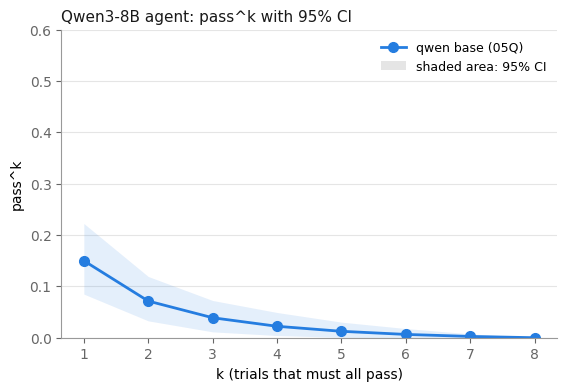

In [9]:
# Why: pass^k (k = 1..8) with 95% CI is the headline metric. ylim stays fixed at 0.6 so every
# Qwen notebook draws on the same axis and 10Q can put the five systems side by side (H7).
import csv, matplotlib.pyplot as plt
from matplotlib.patches import Patch
curves = {name: passk.curve(f"{ROOT}/{d}", N_TASKS)[1] for name, d, _ in ARMS}
show(pd.DataFrame([{"arm": n, **{f"k={r['k']}": round(r["pass^k"], 3) for r in rows},
                    "95% CI k=1": f"[{rows[0]['ci_low']:.2f}, {rows[0]['ci_high']:.2f}]",
                    "drop 1→8": f"{1 - rows[-1]['pass^k'] / rows[0]['pass^k']:.0%}" if rows[0]["pass^k"] else "-"}
                   for n, rows in curves.items() if rows]))
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, d, color in ARMS:
    r = curves[name]
    if not r: continue
    with open(f"{ROOT}/{d}_passk.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=r[0].keys()); w.writeheader(); w.writerows(r)
    ks = [x["k"] for x in r]
    ax.fill_between(ks, [x["ci_low"] for x in r], [x["ci_high"] for x in r], color=color, alpha=0.12, lw=0)
    ax.plot(ks, [x["pass^k"] for x in r], "-", marker="o", ms=7, lw=2, color=color, label=name)
ax.set(xlabel="k (trials that must all pass)", ylabel="pass^k", ylim=(0, 0.6), xticks=range(1, 9))
ax.set_title("Qwen3-8B agent: pass^k with 95% CI", loc="left", fontsize=11, color="#191919")
ax.spines[["top", "right"]].set_visible(False)
for s in ("left", "bottom"): ax.spines[s].set_color("#999999")
ax.tick_params(colors="#666666"); ax.grid(axis="y", color="#e5e5e5", lw=0.8); ax.set_axisbelow(True)
handles, _ = ax.get_legend_handles_labels()
handles.append(Patch(facecolor="#999999", alpha=0.25, label="shaded area: 95% CI"))
ax.legend(handles=handles, frameon=False, fontsize=9)
os.makedirs(f"{ROOT}/figures", exist_ok=True)
plt.savefig(f"{ROOT}/figures/{OUT}_passk.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
# Why: the brief asks for more than pass^k (F3-F7). From the saved dialogues this cell counts:
#  - illegal tool calls: rule-breaking write calls that really ran (same checker as every arm)
#  - dialogue-level (proxy for G1 "explicit yes before the action"): a write call whose last user
#    message has no yes / confirm / go ahead
#  - argument errors: write calls the database rejected ("Error: ..."), i.e. wrong arguments
#  - turn position of illegal calls: early / middle / late third of the dialogue
#  - violations on dialogues that still PASS on the final state (what state-only scoring hides)
# The counting logic is frozen (the summary numbers came from it). The totals are saved for 10Q.
import json, re, time, importlib, violations as V, policy_checker as pc
importlib.reload(V); importlib.reload(pc)
from tau_bench.envs.airline.data import load_data
graph = pc.load_graph()
YES = re.compile(r"\b(yes|yeah|yep|yup|confirm(ed)?|go ahead|proceed|sure|please do|do it|sounds good|"
                 r"that'?s (fine|correct|right)|ok(ay)?|correct)\b", re.I)
G1_TOOLS = {"book_reservation", "update_reservation_flights", "update_reservation_baggages",
            "update_reservation_passengers"}

def scan(traj):
    # replay like violations.py, but keep where in the dialogue each write call happened
    traj = [m for m in traj if isinstance(m, dict)]
    obs = {m["tool_call_id"]: m["content"] for m in traj if m.get("role") == "tool"}
    data, hist, last_user = load_data(), [], ""
    out = {"illegal": 0, "pos": [], "g1_calls": 0, "g1_miss": 0, "arg_err": 0}
    for i, m in enumerate(traj):
        if m.get("role") == "user":
            last_user = m.get("content") or ""
        if m.get("role") != "assistant":
            continue
        for c in m.get("tool_calls") or []:
            if c["id"] not in obs: continue
            name = c["function"]["name"]
            try: kw = json.loads(c["function"]["arguments"] or "{}")
            except json.JSONDecodeError: kw = None
            if name not in V.TOOLS or not isinstance(kw, dict): continue
            o = str(obs[c["id"]]); blocked = o.startswith(V.BLOCK_TAG)
            if name in pc.WRITE_TOOLS:
                if not blocked and pc.check(name, kw, data, hist, graph):
                    out["illegal"] += 1; out["pos"].append(i / max(len(traj) - 1, 1))
                if name in G1_TOOLS:
                    out["g1_calls"] += 1; out["g1_miss"] += not YES.search(last_user)
                if o.startswith("Error") and not blocked:
                    out["arg_err"] += 1
            if blocked: continue
            try: res = V.TOOLS[name].invoke(data=data, **kw)
            except Exception as e: res = f"Error: {e}"
            if name in pc.WRITE_TOOLS and not str(res).startswith("Error"):
                hist.append({"name": name, "kwargs": kw})
    return out

rows, t0 = [], time.time()
for name, d, _ in ARMS:
    tot = {"illegal": 0, "g1_calls": 0, "g1_miss": 0, "arg_err": 0, "early": 0, "middle": 0, "late": 0,
           "passed dialogues": 0, "passed with ≥1 illegal": 0}
    for tasks in tab_of(d).values():
        for r in tasks.values():
            s = scan(r.get("traj") or [])
            for k in ("illegal", "g1_calls", "g1_miss", "arg_err"): tot[k] += s[k]
            for p in s["pos"]: tot["early" if p < 1 / 3 else "middle" if p < 2 / 3 else "late"] += 1
            if r["reward"] >= 1 - 1e-6:
                tot["passed dialogues"] += 1; tot["passed with ≥1 illegal"] += s["illegal"] > 0
    json.dump(tot, open(f"{ROOT}/{d}_violations.json", "w"), indent=2)
    rows.append({"arm": name, "illegal calls run": tot["illegal"],
                 "early / middle / late": f'{tot["early"]} / {tot["middle"]} / {tot["late"]}',
                 "G1: write without a yes": f'{tot["g1_miss"]}/{tot["g1_calls"]}',
                 "argument errors": tot["arg_err"],
                 "passing dialogues with a violation": f'{tot["passed with ≥1 illegal"]}/{tot["passed dialogues"]}'})
show(pd.DataFrame(rows))
print(f"scanned in {time.time() - t0:.0f} s; saved {OUT}_violations.json")

arm,illegal calls run,early / middle / late,G1: write without a yes,argument errors,passing dialogues with a violation
qwen base (05Q),339,86 / 90 / 163,342/571,229,5/60


scanned in 22 s; saved results_qwen_base_violations.json


In [11]:
# Why: which tasks the baseline solves every time, never, or only sometimes. The "sometimes"
# tasks are where a KiL pipeline can make the agent more consistent. Saved for 10Q.
full = {t: v for t, v in tab_of(OUT).items() if len(v) == N_TASKS}
c = passk.success_counts(full, range(N_TASKS))
cons = {"always pass": len([t for t in c if c[t] == N_TRIALS]),
        "sometimes": len([t for t in c if 0 < c[t] < N_TRIALS]),
        "never pass": len([t for t in c if c[t] == 0])}
json.dump(cons, open(f"{ROOT}/{OUT}_consistency.json", "w"), indent=2)
show(pd.DataFrame([{"type": k, "tasks": v} for k, v in cons.items()]))

type,tasks
always pass,0
sometimes,18
never pass,32


## Summary
Rerun on 2026-11-25 with vLLM 0.34.0 on an L4 (24k context, max-num-seqs 8), 50 tasks × 8 trials, 400/400 done, 0 errors, 158 min.

| | pass^1 (95% CI) | pass^8 | drop 1→8 | illegal calls run | G1 no-yes | passing with a violation |
|---|---|---|---|---|---|---|
| **Qwen base (05Q)** | 0.150 [0.09, 0.22] | 0.000 | 100% | 339 | 342/571 | 5/60 |

- Passed per trial: 6 / 8 / 7 / 5 / 8 / 7 / 11 / 8
- Always / sometimes / never pass: 0 / 18 / 32
- Illegal calls by turn position (early / middle / late): 86 / 90 / 163
- Argument errors: 229
- The first run (older vLLM, kept as `results_qwen_base_old_v1`) gave pass^1 0.147 and 338 illegal calls: the same within noise.

**Next:** 06Q, Qwen validator.